# Re-training a Gradient Boosting grapevine phenology predictor (9 stages)

Reproduction of the machine-learning demonstration in:
**Francisco José Lacueva-Pérez et al., "Developing machine learning models from multisourced
real-world datasets to enhance smart-farming practices", Computers and Electronics in Agriculture
231 (Apr 2025), art. 110018**, DOI [10.1016/j.compag.2025.110018](https://doi.org/10.1016/j.compag.2025.110018).

**Scope (partial demonstration).** Re-train ONE algorithm — the `GradientBoostingClassifier`
pipeline of the authors' notebook `src/main/nb_models/Fenologia_models_all_data-GB-parcels.ipynb`
([fjlacueva/GrapevinePhenologyCode](https://github.com/fjlacueva/GrapevinePhenologyCode), CC0-1.0) —
on the authors' public combined dataset
["A Multisource Grapevine Phenology Dataset for Smart Farming and AI Modeling"](https://zenodo.org/records/20124340)
(CC-BY-4.0; 492 MB semicolon-separated CSV) to predict the phenological stage **one week ahead**,
with the authors' parcel-level train/validation/test split and MCC-oriented Optuna selection.
**Not** reproduced here: the other compared algorithms, the authors' full 500-chunk Optuna
search, Sentinel-2 image processing, dataset construction from raw sources, and the
disease-prediction pipeline. Results from this small re-training are **not comparable** to the
paper's published metrics.

**Known dataset defect (verified):** in every Zenodo version the `date` column contains only
`00:00.0`, so the authors' sort-by-date `shift(-7)` construction cannot run as written. This
notebook uses the documented equivalent: a `(parcel, season, day+7)` merge on the `day`
(day-of-year) column; rows without a record exactly 7 days later are excluded (see cell 8).

**Execution status:** executed end-to-end on a fresh **CPU** Colab runtime. The authors'
scikit-learn Gradient Boosting path uses no GPU, so CPU is the only faithful runtime.
**Expected wall time ≈ 35–60 min** (measured on the validation run: download ≈ 4 min,
Optuna search 5 trials + final fit dominates the rest); downloads ≈ 0.5 GB.

**日本語まとめ:** 著者公開コードの Gradient Boosting パイプラインを、著者公開の Zenodo
統合データセット（CC-BY-4.0, 492 MB）で再学習し、1 週間先のフェノロジーステージを予測・評価します。
CPU ランタイム専用です。全アルゴリズム比較・完全な Optuna 探索・Sentinel-2 処理は対象外です。
公開データの `date` 列は全バージョンで壊れているため、`day`（DOY）に基づく等価な
7 日先ターゲット構築を用います（詳細は各セルの説明）。

**Runtime:** select **CPU** (Runtime ▸ Change runtime type ▸ CPU). Then *Run all*.


## 1. Environment setup

Installs Optuna (the authors' hyperparameter framework) and verifies the scientific stack.
The authors' `loss='deviance'` was removed from modern scikit-learn; we use its identical
successor `loss='log_loss'` (same deviance objective) — the only model-definition change.

*環境セットアップ。Optuna を導入し、scikit-learn のバージョンを確認します。*


In [ ]:
import sys, subprocess, importlib
print(sys.version)
for pkg in ("pandas", "numpy", "sklearn", "matplotlib"):
    m = importlib.import_module(pkg)
    print(pkg, m.__version__)
rc = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna>=4,<5"]).returncode
assert rc == 0
import optuna
print("optuna", optuna.__version__)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


pandas 2.2.3
numpy 2.1.3


sklearn 1.6.1
matplotlib 3.10.0


optuna 4.9.0


## 2. Download the stage-mapping table (small file first)

`DIF_phenologicalstages.csv` (593 B) maps `phenologystageid` values to BBCH codes and
descriptions. Downloading it first confirms the Zenodo record-API content route works before
the 492 MB download. The md5 must equal the value published in the record metadata
(`531d76ffb18996fa48e9b0da2f7b6fc9`). The file is semicolon-separated with CRLF line endings.

*まず小さなステージ対応表を取得し、md5 を検証します。*


In [ ]:
import hashlib, time, urllib.request
import pandas as pd

REC = "https://zenodo.org/api/records/20124340/files"

def zenodo_fetch(name: str, timeout: int = 300) -> bytes:
    """Fetch a file from the pinned Zenodo record with bounded retries."""
    url = f"{REC}/{name}/content"
    last = None
    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                return r.read()
        except Exception as exc:
            last = exc
            time.sleep(5 * (attempt + 1))  # short bounded backoff
    raise RuntimeError(f"download failed for {name}: {last!r}")

stage_bytes = zenodo_fetch("DIF_phenologicalstages.csv")
stage_md5 = hashlib.md5(stage_bytes).hexdigest()
assert stage_md5 == "531d76ffb18996fa48e9b0da2f7b6fc9", stage_md5
open("/content/DIF_phenologicalstages.csv", "wb").write(stage_bytes)
print("stage mapping OK:", len(stage_bytes), "bytes, md5", stage_md5)

stage mapping OK: 593 bytes, md5 531d76ffb18996fa48e9b0da2f7b6fc9


## 3. Show the stage mapping

Displays the mapping table. It lists **11 ids (0–10)**: the paper's 9 predicted phenological
stages (BBCH 11–81) plus id 0 (BBCH 00, winter dormancy) and id 10 (BBCH 99, others/after
ripening). The authors' training notebook does not filter labels, so all observed ids are
kept as classes; the classification report below shows them individually.

*ステージ対応表を表示します（11 id: 論文の 9 ステージ + 休眠 0 + その他 10）。*


In [ ]:
stages = pd.read_csv("/content/DIF_phenologicalstages.csv", sep=";")
stages

,itainnovaid,bbch,Descripción BBCH
0,0,0,Winter dormancy or resting period
1,3,63,Early flowering: 30% of flowerhoods fallen
2,1,11,First leaf unfolded and spread away from shoot
3,2,15,5 leaves unfolded
4,4,65,Full flowering: 50% of flowerhoods fallen
5,6,71,"Fruit set: young fruits begin to swell, remain..."
6,5,68,80% of flowerhoods fallen
7,7,75,50% of fruits have reached final size or fruit...
8,8,77,70% of fruits have reached final size or fruit...
9,9,81,Beginning of ripening or fruit colouration


## 4. Download the combined dataset (492,597,434 B) and verify its checksum

Streams the authors' designated combined training matrix
`DIF_GrapevinePehologyDataset.csv` from the pinned Zenodo record (20124340; latest version
of concept [10.5281/zenodo.17930722](https://doi.org/10.5281/zenodo.17930722); the v1.0
record 17930723 ships byte-identical files) directly to the Colab VM under `/content`,
hashing while streaming. Accepted only if size and md5 match the record metadata
(`9166e31204a5b10b035fed902f0c86a8`). Takes a few minutes.

*492 MB の統合データセットをストリーミングダウンロードし、サイズと md5 を検証します（数分）。*


In [ ]:
BIG = "/content/DIF_GrapevinePehologyDataset.csv"
url = f"{REC}/DIF_GrapevinePehologyDataset.csv/content"
t0 = time.time()
hasher = hashlib.md5()
n = 0
with urllib.request.urlopen(url, timeout=600) as r, open(BIG, "wb") as f:
    while True:
        chunk = r.read(1 << 22)
        if not chunk:
            break
        hasher.update(chunk)
        f.write(chunk)
        n += len(chunk)
        if n % (64 << 20) < (1 << 22):
            print(f"{n/1e6:.0f} MB, {time.time()-t0:.0f}s", flush=True)
digest = hasher.hexdigest()
assert n == 492597434, n
assert digest == "9166e31204a5b10b035fed902f0c86a8", digest
print(f"dataset OK: {n} bytes in {time.time()-t0:.0f}s, md5 {digest}")

67 MB, 1s


134 MB, 1s


201 MB, 2s


268 MB, 4s


336 MB, 5s


403 MB, 6s


470 MB, 7s


dataset OK: 492597434 bytes in 7s, md5 9166e31204a5b10b035fed902f0c86a8


## 5. Verify the actual columns against the dataset documentation

The dataset's `DIF_DescriptionOfTheDataset.pdf` documents the schema; we still verify the
byte-level truth here (the file is semicolon-separated and the parcel column is
`cadastralcode`, matching the authors' training notebook rather than the `codigo` used in
their Test-notebook variant). The run aborts if a column required by the reproduction is
absent.

*ヘッダのみ読み込み、再現に必要な列名（セミコロン区切り、`cadastralcode` 等）を検証します。*


In [ ]:
head = pd.read_csv(BIG, nrows=2, sep=";", low_memory=False)
cols = list(head.columns)
print(len(cols), "columns in file")
REQUIRED = ["phenologystageid", "cadastralcode", "season", "day", "PDO_id",
            "min", "MAX", "mean", "std", "median", "diff",
            "longitude", "latitude", "altitudeASL"]
missing = [c for c in REQUIRED if c not in cols]
VAR_ONEHOT = sorted(c for c in cols if c.startswith("variety_"))
PDO_ONEHOT = sorted(c for c in cols if c.startswith("PDO_") and c != "PDO_id")
print("variety one-hots:", VAR_ONEHOT)
print("PDO one-hots:", PDO_ONEHOT)
assert not missing, f"missing required columns: {missing}"


591 columns in file
variety one-hots: ['variety_CABERNET SAUVIGNON', 'variety_CHARDONNAY', 'variety_GARNACHA', 'variety_MAZUELA', 'variety_SYRACH', 'variety_TEMPRANILLO']
PDO one-hots: ['PDO_Borja', 'PDO_Calatayud', 'PDO_Carinena', 'PDO_Somontano']


## 6. Load the required columns and profile the table

Reads only the columns used by this reproduction (bounding memory on the 492 MB file) and
deduplicates as the authors do. Reports the row count, parcel count, seasons, and stage
distribution that the model is trained on.

*必要な列のみ読み込み（メモリ削減）、行数・parcel 数・シーズン・ステージ分布を確認します。*


In [ ]:
USECOLS = REQUIRED + VAR_ONEHOT + PDO_ONEHOT
t0 = time.time()
sabana = pd.read_csv(BIG, usecols=USECOLS, sep=";", low_memory=False).drop_duplicates()
print(f"loaded {sabana.shape} in {time.time()-t0:.0f}s; "
      f"memory {sabana.memory_usage(deep=True).sum()/1e6:.0f} MB")
print("parcels:", sabana["cadastralcode"].nunique())
print("seasons:", sorted(sabana["season"].dropna().unique()))
print("PDO groups:", sabana["PDO_id"].value_counts().to_dict())
stage_counts = sabana["phenologystageid"].value_counts().sort_index()
print(stage_counts)

loaded (104377, 24) in 6s; memory 36 MB
parcels: 98
seasons: ['2015_2016', '2016_2017', '2017_2018', '2018_2019', '2019_2020', '2020_2021', '2021_2022']
PDO groups: {'Carinena': 68174, 'Borja': 28918, 'Calatayud': 7096, 'Somontano': 189}
phenologystageid
0     37023
1      7826
2      4649
3      9184
4      1395
5      1174
6      1044
7      2481
8      3686
9      9832
10    26083
Name: count, dtype: int64


## 7. Input preview: class balance of the stage labels

A data-appropriate preview of the actual input: the distribution of records over the
phenological stage ids. Strong class imbalance matters when reading the accuracy/MCC results
later. This graph was created for this notebook (not an author figure).

*入力プレビュー: ステージ id ごとのレコード数（本ノートブックで作成した図であり、論文の図ではありません）。*


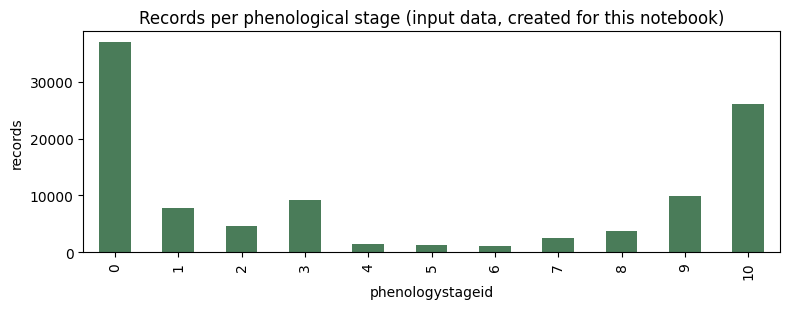

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.2))
stage_counts.plot.bar(ax=ax, color="#4a7c59")
ax.set_xlabel("phenologystageid")
ax.set_ylabel("records")
ax.set_title("Records per phenological stage (input data, created for this notebook)")
fig.tight_layout()
plt.show()

## 8. 7-day-ahead target construction (documented equivalent of the authors' `shift(-7)`)

The authors order each parcel's rows by date, shift by 7 positions, and keep rows whose gap
is exactly 7 days. The published `date` column cannot support this (it contains only
`00:00.0` in every Zenodo version), so we use the equivalent set-based construction: for
each record, look up the record of the **same parcel and season exactly 7 day-of-year units
later** (`day + 7`) and take its `phenologystageid` as `next_pheno`. Records with an
ambiguous `(parcel, season, day)` key (1,280 rows from multiple climatic stations) and
pairs crossing the December→January year boundary (no `day+7` match) are excluded; about
87% of rows retain a label. Because a season's day values do not repeat across its two
calendar years, a `day+7` match is always the true next-week record.

*公開データの `date` 列は壊れているため、(parcel, season, day+7) のマージという等価手法で
翌週ステージ `next_pheno` を構築します（曖昧キー・年跨ぎペアは除外、約 87% の行にラベルが付きます）。*


In [ ]:
key = ["cadastralcode", "season", "day"]
dupmask = sabana.duplicated(subset=key, keep=False)
print("rows in ambiguous (parcel, season, day) groups:", int(dupmask.sum()))
clean = sabana[~dupmask]
target_map = clean[key + ["phenologystageid"]].rename(
    columns={"day": "day_p7", "phenologystageid": "next_pheno"})
target_map["day_p7"] = target_map["day_p7"].astype(int) + 7
datos_total = clean.merge(target_map, left_on=key,
                          right_on=["cadastralcode", "season", "day_p7"],
                          how="inner").drop(columns="day_p7")
print("rows with a 7-day-ahead label:", len(datos_total), "of", len(clean))
print(datos_total["next_pheno"].value_counts().sort_index().to_dict())

rows in ambiguous (parcel, season, day) groups: 1280
rows with a 7-day-ahead label: 89290 of 103097
{0: 32953, 1: 6464, 2: 3899, 3: 8093, 4: 1200, 5: 1021, 6: 874, 7: 2219, 8: 3250, 9: 8925, 10: 20392}


## 9. Parcel-level train/validation/test split (authors' procedure)

The authors split **parcels, not rows** — per PDO group (`doc_id` in their internal DB;
`PDO_id` here, the public equivalent) they assign 60% of parcels to training and split the
rest into validation/test with `random_state=17`. This keeps whole vineyards out of the
evaluation.

*著者の手順どおり、行ではなく parcel 単位で PDO ごとに 60/20/20 分割します。*


In [ ]:
from sklearn.model_selection import train_test_split

parcelas_train, parcelas_test, parcelas_vali = [], [], []
for pdo in datos_total["PDO_id"].dropna().unique():
    parcels_do = list(datos_total.loc[datos_total["PDO_id"] == pdo, "cadastralcode"].unique())
    tr, rest = train_test_split(parcels_do, random_state=17, test_size=0.4)
    parcelas_train += tr
    if len(rest) > 1:
        vali, test = train_test_split(rest, test_size=0.5, random_state=17)
        parcelas_vali += vali
        parcelas_test += test
    else:
        parcelas_test += rest
print("parcels  train/vali/test:", len(parcelas_train), len(parcelas_vali), len(parcelas_test))

parcels  train/vali/test: 57 20 21


## 10. Feature set and train/validation/test frames

Baseline feature set of the authors' `objective()`: the current stage (`phenologystageid`),
day-of-year (`day`), the six NDVI-derived parcel statistics (`min, MAX, mean, std, median,
diff`), the `variety_*` and `PDO_*` one-hot flags, plus parcel coordinates and altitude
(`altitudeASL` renamed to the authors' `altitud`). The accumulated-weather and daily-lag
branches of the authors' Optuna search are out of scope for this minimal demo (documented
adaptation). Rows with missing features are dropped, as in the authors'
`train[medidas].dropna()`.

*著者のベースライン特徴量（現在ステージ・DOY・NDVI 統計・品種/PDO フラグ・座標・標高）を準備し、
train/validation/test フレームを作成します。天候蓄積変数の探索は対象外です。*


In [ ]:
FEATURES = (["phenologystageid", "day", "min", "MAX", "mean", "std", "median", "diff"]
            + VAR_ONEHOT + PDO_ONEHOT + ["longitude", "latitude"])
TARGET = "next_pheno"

def prep(frame):
    out = frame.rename(columns={"altitudeASL": "altitud"})[
        ["cadastralcode", "season", "altitud"] + FEATURES + [TARGET]].dropna().copy()
    return out.drop(columns=["cadastralcode", "season"])

train = prep(datos_total[datos_total["cadastralcode"].isin(parcelas_train)])
vali = prep(datos_total[datos_total["cadastralcode"].isin(parcelas_vali)])
test = prep(datos_total[datos_total["cadastralcode"].isin(parcelas_test)])
print("rows  train/vali/test:", len(train), len(vali), len(test))

rows  train/vali/test: 51914 18887 18489


## 11. Optuna search over model capacity (authors' objective, bounded)

The authors select hyperparameters by maximizing validation **MCC** with Optuna
(`TPESampler(seed=17)`) over `n_estimators` 32–512 (step 32), `max_depth` 3–10,
`min_samples_leaf` 0.05–0.2 (step 0.01) and `learning_rate` 0.005–10 (step 0.005), with
`validation_fraction=0.3`, `n_iter_no_change=15`, `tol=1e-4`, `random_state=17` (and
`loss='log_loss'`, see cell 1). We run the same objective with a bounded budget of
**5 trials** — half the authors' per-chunk budget of 10; their full search ran
500 chunks and is out of scope. The coordinate flags are searched exactly as the authors
do. Expect roughly 2–10 minutes per trial depending on early stopping.

*著者の objective（MCC 最大化）を 5 試行だけ実行します（完全な 500 チャンク探索は対象外）。*


In [ ]:
import optuna
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import matthews_corrcoef, accuracy_score, f1_score

def objective(trial):
    measures = list(FEATURES)
    if trial.suggest_categorical("Altitud", [True, False]):
        measures.append("altitud")
    if trial.suggest_categorical("Latitud", [True, False]):
        measures.append("latitude")
    if trial.suggest_categorical("Longitud", [True, False]):
        measures.append("longitude")

    tr_x = train[measures + [TARGET]].dropna()
    va_x = vali[measures + [TARGET]].dropna()
    X_train, y_train = tr_x[measures], tr_x[TARGET]
    X_vali, y_vali = va_x[measures], va_x[TARGET]

    params = {"random_state": 17, "loss": "log_loss",
              "n_estimators": int(trial.suggest_float("n_estimators", low=32, high=512, step=32)),
              "validation_fraction": 0.3, "n_iter_no_change": 15, "tol": 1e-4,
              "max_depth": trial.suggest_int("max_depth", low=3, high=10),
              "min_samples_leaf": float(trial.suggest_float("min_samples_leaf", low=0.05, high=0.2, step=0.01)),
              "learning_rate": trial.suggest_float("learning_rate", low=5e-3, high=10, step=5e-3)}
    model = GradientBoostingClassifier(**params).fit(X_train, y_train)
    preds = model.predict(X_vali)
    return matthews_corrcoef(y_vali, preds)

sampler = optuna.samplers.TPESampler(seed=17)
study = optuna.create_study(study_name="Fenologia", direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=5)
print("best validation MCC:", study.best_value)
print("best params:", study.best_params)

[I 2026-10-26 01:09:30,821] A new study created in memory with name: Fenologia


[I 2026-10-26 01:10:03,098] Trial 0 finished with value: 0.1719990951965645 and parameters: {'Altitud': False, 'Latitud': True, 'Longitud': True, 'n_estimators': 352.0, 'max_depth': 7, 'min_samples_leaf': 0.05, 'learning_rate': 3.58}. Best is trial 0 with value: 0.1719990951965645.


[I 2026-10-26 01:10:20,223] Trial 1 finished with value: 0.31246448494950574 and parameters: {'Altitud': True, 'Latitud': False, 'Longitud': False, 'n_estimators': 288.0, 'max_depth': 7, 'min_samples_leaf': 0.12000000000000001, 'learning_rate': 2.83}. Best is trial 1 with value: 0.31246448494950574.


[I 2026-10-26 01:10:35,795] Trial 2 finished with value: 0.2007742005438682 and parameters: {'Altitud': False, 'Latitud': False, 'Longitud': True, 'n_estimators': 96.0, 'max_depth': 3, 'min_samples_leaf': 0.16, 'learning_rate': 2.925}. Best is trial 1 with value: 0.31246448494950574.


[I 2026-10-26 01:10:55,513] Trial 3 finished with value: 0.0672155722485354 and parameters: {'Altitud': False, 'Latitud': True, 'Longitud': True, 'n_estimators': 352.0, 'max_depth': 3, 'min_samples_leaf': 0.12000000000000001, 'learning_rate': 8.88}. Best is trial 1 with value: 0.31246448494950574.


[I 2026-10-26 01:11:11,735] Trial 4 finished with value: 0.029259802388434085 and parameters: {'Altitud': True, 'Latitud': True, 'Longitud': False, 'n_estimators': 480.0, 'max_depth': 4, 'min_samples_leaf': 0.16999999999999998, 'learning_rate': 8.38}. Best is trial 1 with value: 0.31246448494950574.


best validation MCC: 0.31246448494950574
best params: {'Altitud': True, 'Latitud': False, 'Longitud': False, 'n_estimators': 288.0, 'max_depth': 7, 'min_samples_leaf': 0.12000000000000001, 'learning_rate': 2.83}


## 12. Train the best configuration and report validation metrics

Retrains the selected configuration on the training parcels (as the authors' `eval_model`
does for the chosen study row) and prints validation MCC / accuracy / macro-F1 — the same
metrics and ranking metric (MCC) the authors use.

*最良構成を再学習し、validation の MCC・Accuracy・macro-F1 を報告します。*


In [ ]:
best = dict(study.best_params)
best["n_estimators"] = int(best["n_estimators"])
best.update({"random_state": 17, "loss": "log_loss", "validation_fraction": 0.3,
             "n_iter_no_change": 15, "tol": 1e-4})
measures = list(FEATURES)
if best.pop("Altitud"): measures.append("altitud")
if best.pop("Latitud"): measures.append("latitude")
if best.pop("Longitud"): measures.append("longitude")

tr_ok = train[measures + [TARGET]].dropna()
model = GradientBoostingClassifier(**best).fit(tr_ok[measures], tr_ok[TARGET])

vali_ok = vali[measures + [TARGET]].dropna()
preds_vali = model.predict(vali_ok[measures])
print("Validation  MCC:", round(matthews_corrcoef(vali_ok[TARGET], preds_vali), 4),
      " accuracy:", round(accuracy_score(vali_ok[TARGET], preds_vali), 4),
      " macro-F1:", round(f1_score(vali_ok[TARGET], preds_vali, average="macro"), 4))

Validation  MCC: 0.3125  accuracy: 0.3611  macro-F1: 0.2624


## 13. Held-out parcel test evaluation with the authors' monotonic correction

On test parcels the authors first keep only rows whose next stage is **not below** the
current stage (`next_pheno >= phenologystageid` — phenology advances monotonically within a
season), predict, then clip any prediction below the current stage up to it (their Test
notebook cell 14). We report MCC, accuracy and the full classification report on those rows.

*テスト parcel で評価します。著者どおり、フェノロジーの単調性修正（現在ステージ以上への clip）を適用します。*


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

test_ok = test[measures + [TARGET]].dropna()
test_mono = test_ok[test_ok[TARGET] >= test_ok["phenologystageid"]]
X_test, y_test = test_mono[measures], test_mono[TARGET]
preds = model.predict(X_test).astype(float)
preds = np.maximum(preds, test_mono["phenologystageid"].to_numpy())
print("test rows (monotone subset):", len(test_mono))
print("MCC:", round(matthews_corrcoef(y_test, preds), 4),
      " accuracy:", round(accuracy_score(y_test, preds), 4))
print(classification_report(y_test, preds, digits=3))

test rows (monotone subset): 15723
MCC: 0.6173  accuracy: 0.6006
              precision    recall  f1-score   support

           0      1.000     0.279     0.436      6909
           1      1.000     0.413     0.585      1063
           2      0.345     0.958     0.507       424
           3      0.992     0.559     0.715      1321
           4      0.003     1.000     0.005        15
           5      0.607     0.327     0.425        52
           6      1.000     1.000     1.000        35
           7      1.000     1.000     1.000        82
           8      1.000     0.987     0.994       314
           9      1.000     0.995     0.997      1280
          10      1.000     0.993     0.997      4228

    accuracy                          0.601     15723
   macro avg      0.813     0.774     0.696     15723
weighted avg      0.979     0.601     0.683     15723



## 14. Confusion matrix of the test prediction

Row-normalized confusion matrix (rows: true next stage, columns: prediction), rendered as
in the authors' Test notebook (`sns.heatmap` on the normalized matrix). This is the main
result graph of this reproduction.

*テスト予測の混同行列（行: 正解の翌週ステージ、列: 予測）。著者の Test ノートブックと同様の可視化です。*


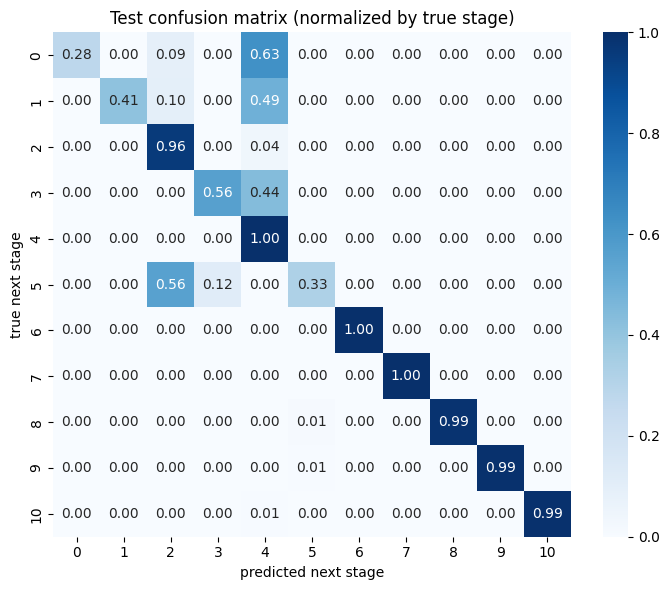

In [ ]:
import seaborn as sns

labels = sorted(pd.unique(y_test))
cf = confusion_matrix(y_test, preds, labels=labels)
cf_norm = cf.T / np.maximum(cf.sum(axis=1), 1)
plt.figure(figsize=(7.2, 6))
sns.heatmap(cf_norm.T, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("predicted next stage"); plt.ylabel("true next stage")
plt.title("Test confusion matrix (normalized by true stage)")
plt.tight_layout()
plt.show()

## 15. Feature importance of the trained model

The authors' `plot_feature_importance`: top-20 Gradient Boosting feature importances. Note
that the paper's best models also included Sentinel-2-derived features; here the NDVI
statistics (`min/MAX/mean/std/median/diff`) are part of the baseline set.

*学習済みモデルの上位 20 特徴量の重要度（著者の plot_feature_importance と同じ可視化）。*


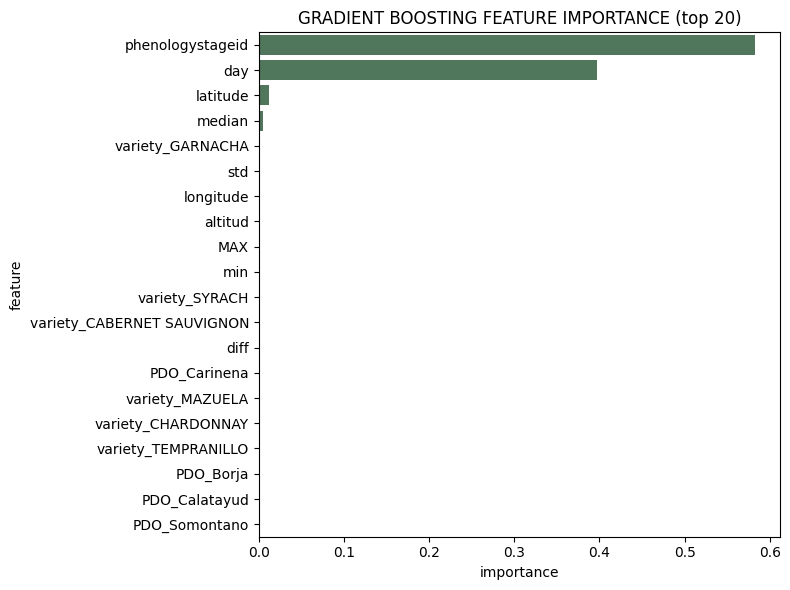

In [ ]:
fi = (pd.DataFrame({"feature": measures, "importance": model.feature_importances_})
      .sort_values("importance", ascending=False).iloc[:20])
plt.figure(figsize=(8, 6))
sns.barplot(x="importance", y="feature", data=fi, color="#4a7c59")
plt.title("GRADIENT BOOSTING FEATURE IMPORTANCE (top 20)")
plt.tight_layout()
plt.show()

## 16. Interpretation and limitations

**What this shows.** A gradient boosting model trained on the authors' public combined
dataset, with their parcel-level split and a 7-day-ahead target construction equivalent to
theirs, distinguishes the grapevine phenological stages on held-out parcels; the MCC /
accuracy / confusion matrix above are computed from actual executed cells, with MCC-based
Optuna selection mirroring the authors' procedure.

**What this does NOT show.** A *partial demonstration*: one algorithm, a bounded
hyperparameter search (5 trials vs the authors' extensive search), the baseline
feature set (no accumulated weather indices or daily lags), and no comparison against the
other algorithms of the paper. Numbers are not comparable to the paper's published results;
they depend on the trial budget and the Colab environment.

**Adaptations (all documented above).** (1) `loss='log_loss'` for the removed `'deviance'`.
(2) `doc_id`→`PDO_id` grouping; the CSV's `cadastralcode` column matches the authors'
training notebook. (3) `altitudeASL`→`altitud`. (4) The broken `date` column (only
`00:00.0` in every Zenodo version) required the cell-8 `(parcel, season, day+7)` merge
instead of date-based `shift(-7)`; ambiguous day keys and year-boundary pairs are excluded.
(5) `suggest_float(step=…)` for deprecated Optuna APIs. (6) Bounded 5-trial search.

**Provenance.** Paper: Comput. Electron. Agric. 231:110018 (2025), DOI
10.1016/j.compag.2025.110018. Code: fjlacueva/GrapevinePhenologyCode (CC0-1.0), notebooks
`src/main/nb_models/Fenologia_models_all_data-GB-parcels.ipynb` and `-GB-Test-parcels.ipynb`.
Data: Zenodo record 20124340 (concept DOI 10.5281/zenodo.17930722), CC-BY-4.0; file checksums
verified above. Schema documentation: `DIF_DescriptionOfTheDataset.pdf` in the same record.

**日本語の要点:** 著者公開データと手順（parcel 単位分割・7 日先ターゲット・MCC 選択）に従い、
Gradient Boosting 1 種を再学習してフェノロジーステージ予測を評価しました。限定的なデモであり、
論文の公表値との比較はできません。`date` 列の欠損に対する等価構築の詳細はセル 8 の説明を参照してください。
